In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"2026-07-02.csv")
df.head()

,date,state,district,market,commodity,variety,grade,min_price,max_price,modal_price
0,2026-07-02,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Ashgourd,Other,FAQ,2500.0,5000.0,3500.0
1,2026-07-02,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Banana,Banana - Ripe,Local,3000.0,6000.0,4500.0
2,2026-07-02,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Banana - Green,Other,FAQ,3000.0,6000.0,4500.0
3,2026-07-02,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Bhindi(Ladies Finger),Other,FAQ,10000.0,18000.0,15000.0
4,2026-07-02,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Black Gram(Urd Beans)(Whole),Other,FAQ,8000.0,12000.0,9500.0


In [3]:

missing = df.isnull().sum()

# Missing percentage
missing_percent = (missing / len(df)) * 100

missing_report = pd.DataFrame({
    'Missing Values': missing,
    'Missing Percentage': missing_percent
})

print(missing_report)

             Missing Values  Missing Percentage
date                      0                 0.0
state                     0                 0.0
district                  0                 0.0
market                    0                 0.0
commodity                 0                 0.0
variety                   0                 0.0
grade                     0                 0.0
min_price                 0                 0.0
max_price                 0                 0.0
modal_price               0                 0.0


In [4]:

print("Duplicate Rows:", df.duplicated().sum())

# Display duplicate records
duplicates = df[df.duplicated(keep=False)]

display(duplicates.head(10))

Duplicate Rows: 0


,date,state,district,market,commodity,variety,grade,min_price,max_price,modal_price


In [5]:

df['date'] = pd.to_datetime(
    df['date'],
    errors='coerce'
)


price_columns = [
    'min_price',
    'max_price',
    'modal_price'
]

for col in price_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

text_columns = df.select_dtypes(include='object').columns

for col in text_columns:
    df[col] = df[col].str.strip()

In [6]:

invalid_range = df[
    df['min_price'] > df['max_price']
]

# Modal price should generally be within the price range
invalid_modal = df[
    (df['modal_price'] < df['min_price']) |
    (df['modal_price'] > df['max_price'])
]

print("Invalid price ranges:", len(invalid_range))
print("Invalid modal prices:", len(invalid_modal))

Invalid price ranges: 0
Invalid modal prices: 0


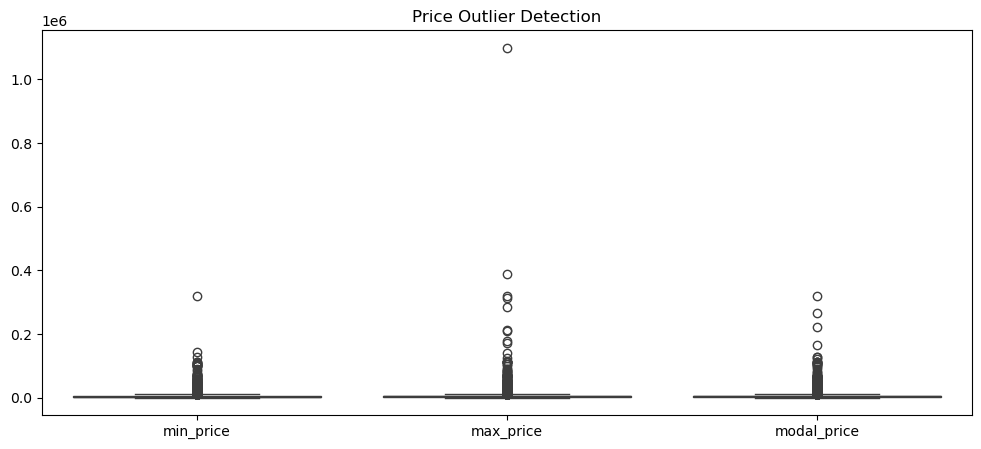

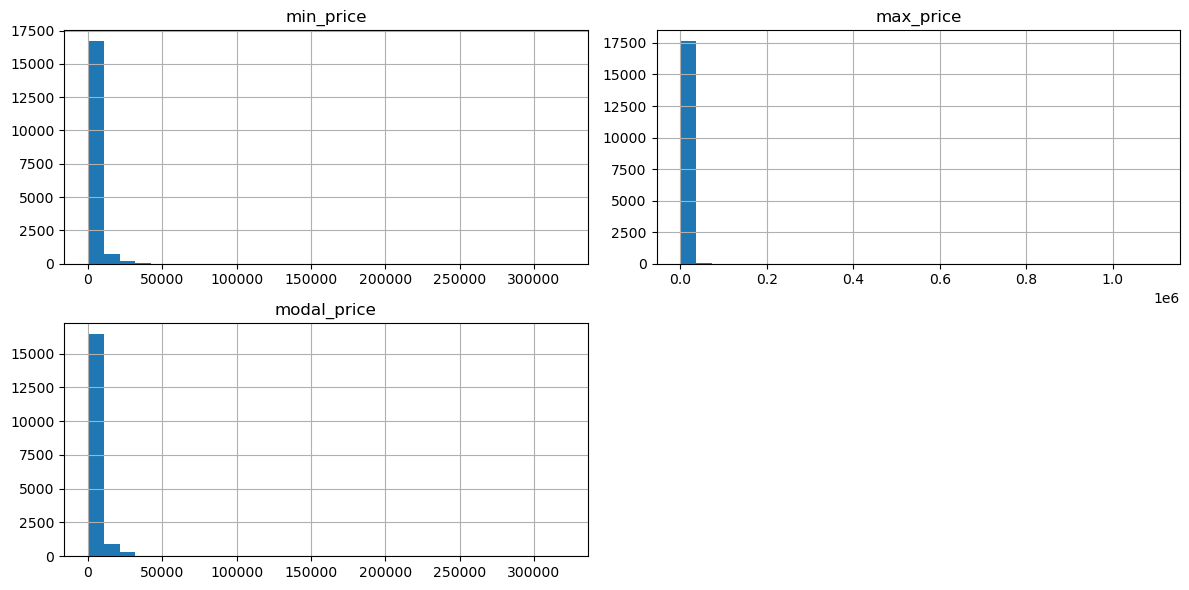

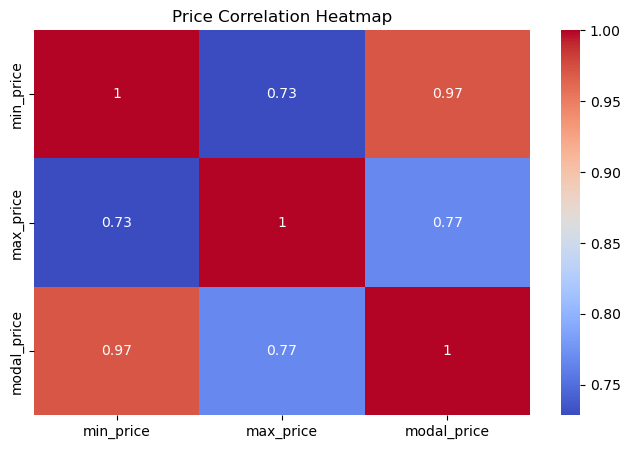

In [7]:

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df[['min_price', 'max_price', 'modal_price']]
)

plt.title("Price Outlier Detection")
plt.show()


df[['min_price', 'max_price', 'modal_price']].hist(
    figsize=(12, 6),
    bins=30
)

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

sns.heatmap(
    df[price_columns].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Price Correlation Heatmap")
plt.show()

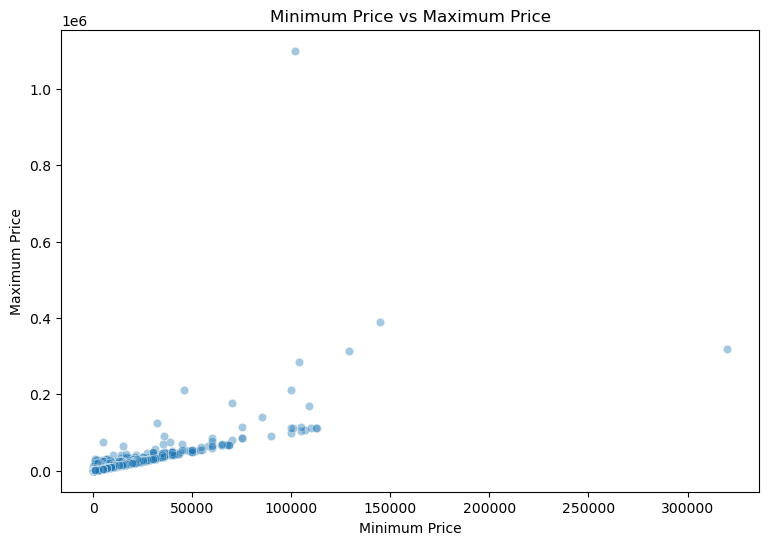

In [9]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='min_price',
    y='max_price',
    alpha=0.4
)

plt.title("Minimum Price vs Maximum Price")
plt.xlabel("Minimum Price")
plt.ylabel("Maximum Price")
plt.show()

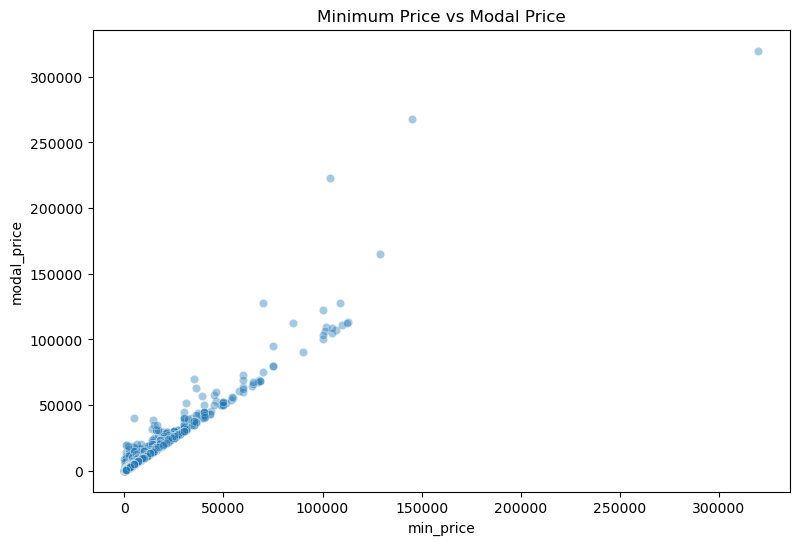

In [10]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='min_price',
    y='modal_price',
    alpha=0.4
)

plt.title("Minimum Price vs Modal Price")
plt.show()

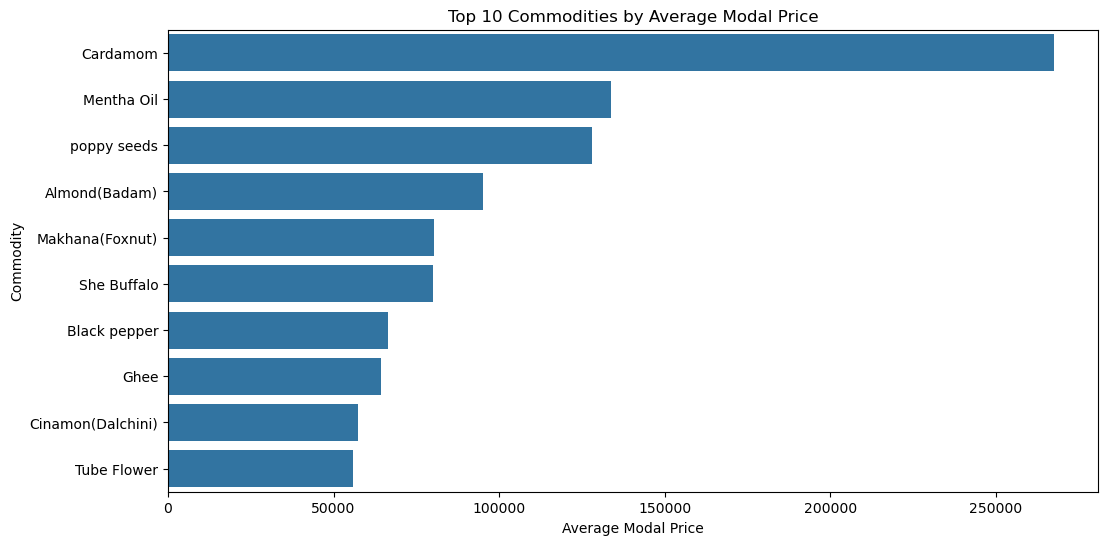

In [11]:
commodity_price = (
    df.groupby('commodity')['modal_price']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=commodity_price.values,
    y=commodity_price.index
)

plt.title("Top 10 Commodities by Average Modal Price")
plt.xlabel("Average Modal Price")
plt.ylabel("Commodity")
plt.show()

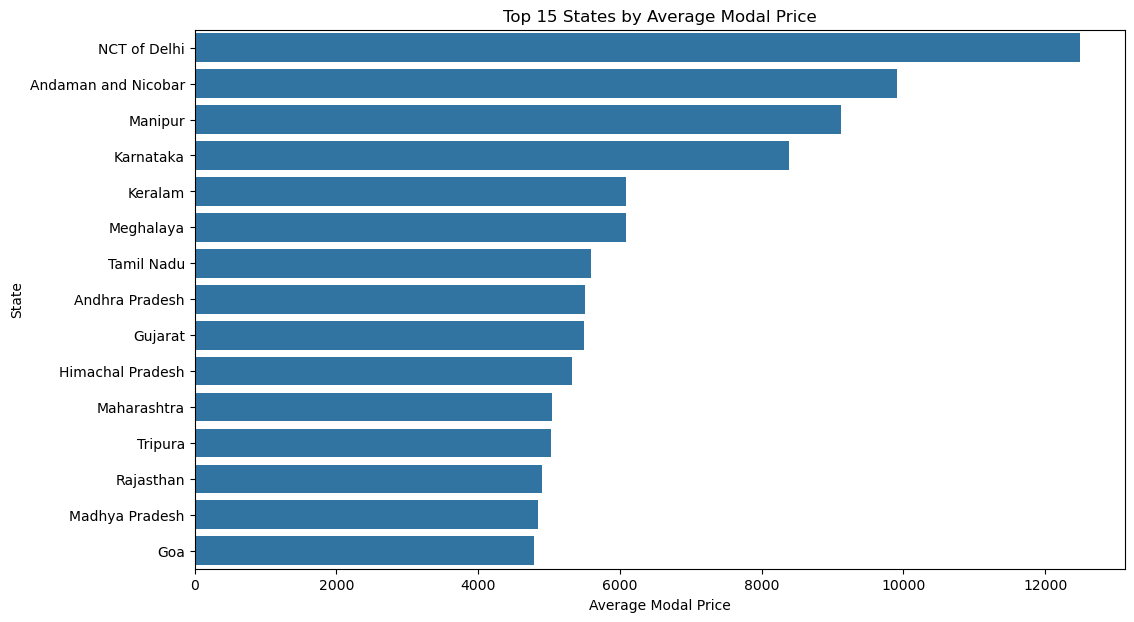

In [12]:
state_price = (
    df.groupby('state')['modal_price']
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=state_price.values,
    y=state_price.index
)

plt.title("Top 15 States by Average Modal Price")
plt.xlabel("Average Modal Price")
plt.ylabel("State")
plt.show()

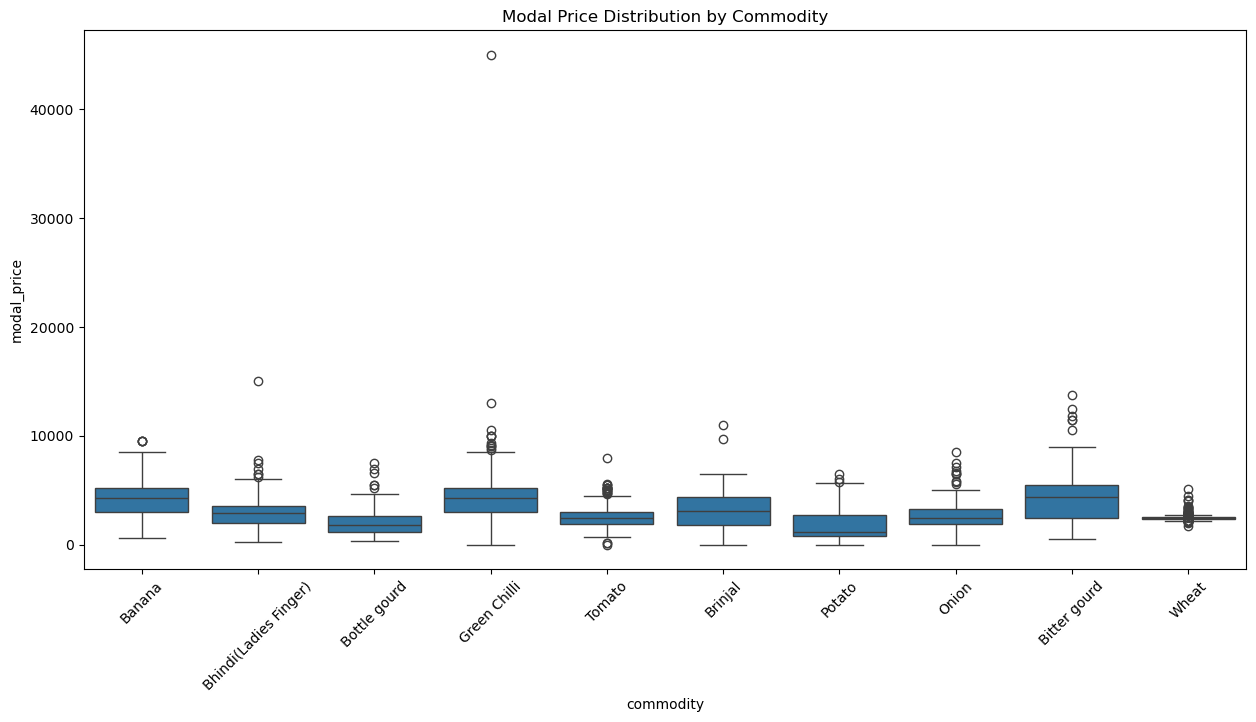

In [13]:
top_commodities = df['commodity'].value_counts().head(10).index

filtered_df = df[df['commodity'].isin(top_commodities)]

plt.figure(figsize=(15, 7))

sns.boxplot(
    data=filtered_df,
    x='commodity',
    y='modal_price'
)

plt.title("Modal Price Distribution by Commodity")
plt.xticks(rotation=45)
plt.show()